# Test of the final network

The network of experiment F (the recipe of B trained on all the labelled training frames, last epoch kept)
is evaluated on the test set in `data/test`, which was never used for training or validation.
To compute the score the IoU of the classes 1 to 8 is computed for every image at the
original resolution, and the mean is taken over all the (image, class) pairs, ignoring the pairs where the class
is in neither the ground truth nor the prediction.

In [1]:
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
sys.path.append("..")
from src import config
from src.data import download_dataset
from src.predict import compare_postprocessing, evaluate, load_model, plot_predictions, predict

## Load the model

`load_model()` reads `config.FINAL_WEIGHTS` (`outputs/experiment_F/final.pt`).

In [2]:
model = load_model()
print(f"device: {model.device} | working resolution: {model.image_size} | batch size: {model.batch_size}")
print(f"post-processing: classes under {model.min_area:.0%} of an image are removed (rare classes {model.rare_classes}: {model.rare_min_area:.0%})")

device: cuda | working resolution: (272, 512) | batch size: 8
post-processing: classes under 2% of an image are removed (rare classes (4, 5): 0%)


## The `predict` function

It accepts one image `(H, W, 3)` or a batch `(batch_size, H, W, 3)` of `uint8`, of any size, and returns the label
maps as `uint8`: `(H, W)` for one image and `(batch_size, H, W, 1)` for a batch.

In [3]:
test_samples = download_dataset(config.TEST_DIR)
print(f"{len(test_samples)} test samples")

from src.data import load_sample
images = np.stack([load_sample(s)[0] for s in test_samples[:5]])

one = predict(model, images[0])
batch = predict(model, images)
print("one image:", images[0].shape, images[0].dtype, "->", one.shape, one.dtype)
print("batch    :", images.shape, images.dtype, "->", batch.shape, batch.dtype)
differing = np.mean(one != batch[0, ..., 0])

145 test samples
one image: (544, 1024, 3) uint8 -> (544, 1024) uint8
batch    : (5, 544, 1024, 3) uint8 -> (5, 544, 1024, 1) uint8


## Score on the test set

The images are given to `predict` one at a time, at full resolution, like the evaluation code of the course.
The evaluation is run twice, without and with the post-processing, to show what the latter adds.

In [4]:
results = compare_postprocessing(model)

summary = pd.DataFrame({
    name: {"score (official)": r.score, "mean class IoU": float(np.nanmean(r.per_class)),
           "pairs with IoU = 0": int((r.iou == 0).sum()), "valid pairs": int((~np.isnan(r.iou)).sum()),
           "frames per second": r.fps, "peak GPU memory (GB)": r.peak_gpu_gb}
    for name, r in results.items()}).round(4)
summary

145 samples | score 0.4794 | 128.2 fps | peak GPU memory 0.14 GB
145 samples | score 0.5106 | 101.3 fps | peak GPU memory 0.14 GB


,plain,post-processed
score (official),0.4794,0.5106
mean class IoU,0.3918,0.4092
pairs with IoU = 0,249.0000,223.0000
valid pairs,841.0000,783.0000
frames per second,128.2428,101.3046
peak GPU memory (GB),0.1436,0.1436


In [5]:
final = results["post-processed"]
print(f"Final test score: {final.score:.4f}")
final.table()

Final test score: 0.5106


,mean IoU,valid images,IoU = 0
smooth trail,0.4029,113,43
traversable grass,0.4784,123,34
rough trail,0.3056,111,51
puddle,0.0000,6,6
obstacle,0.2805,51,24
non-traversable low vegetation,0.1931,95,55
high vegetation,0.7780,145,1
sky,0.8350,139,9


### Where the score is lost

The table shows, for every class, the mean IoU over the images where the class counts, how many images those are,
and in how many of them the IoU is exactly 0 (the class is missed, or predicted where it is not present).

best images : {'0144': 0.978, '0020': 0.969, '0041': 0.961}
worst images: {'0111': 0.127, '0132': 0.171, '0015': 0.178}


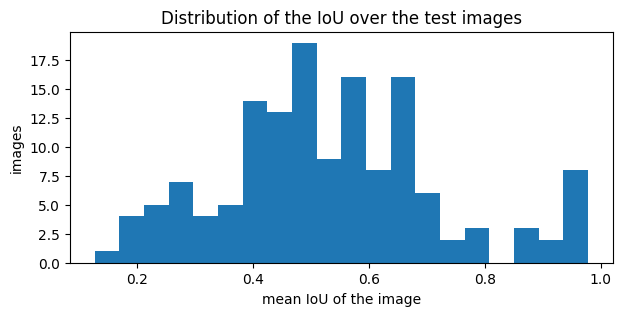

In [6]:
per_image = pd.Series(final.per_image, index=[s.name for s in final.samples], name="IoU of the image")
print("best images :", per_image.nlargest(3).round(3).to_dict())
print("worst images:", per_image.nsmallest(3).round(3).to_dict())

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(final.per_image, bins=20)
ax.set_xlabel("mean IoU of the image")
ax.set_ylabel("images")
ax.set_title("Distribution of the IoU over the test images")
plt.show()

## Examples

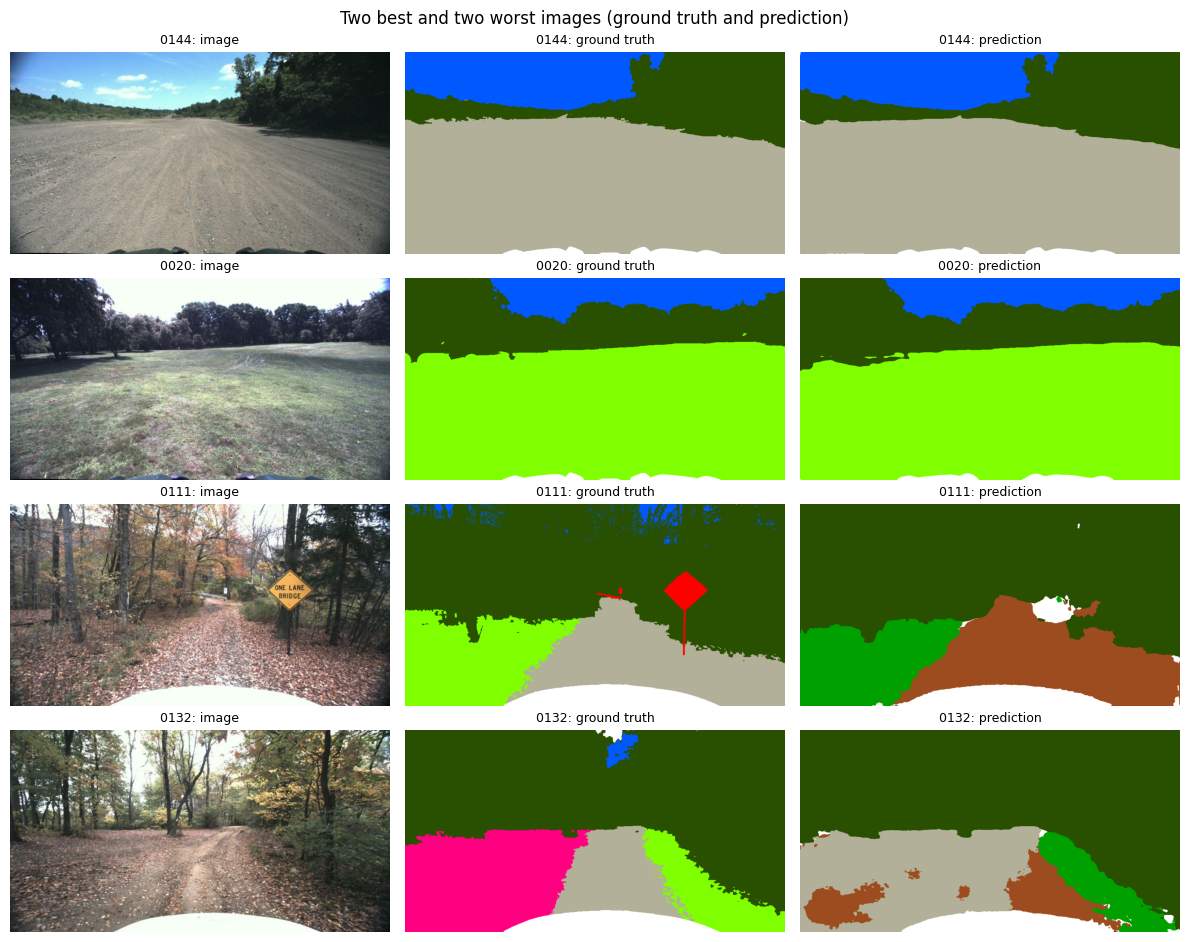

In [7]:
best = list(per_image.nlargest(2).index)
worst = list(per_image.nsmallest(2).index)
by_name = {s.name: s for s in final.samples}
chosen = [by_name[n] for n in best + worst]
plot_predictions(model, chosen, title="Two best and two worst images (ground truth and prediction)")
plt.show()